In [0]:
# Databricks notebook: 02_state_transaction_forecasting
# Purpose: Predict next-quarter PhonePe transaction counts
# for every Indian state and union territory.

# ============================================================
# 1. IMPORTS AND REPRODUCIBILITY
# ============================================================

import sys
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

from sklearn.compose import (
    ColumnTransformer,
    TransformedTargetRegressor
)

from sklearn.pipeline import Pipeline

from sklearn.preprocessing import (
    OneHotEncoder,
    StandardScaler
)

from sklearn.impute import SimpleImputer

from sklearn.linear_model import Ridge

from sklearn.ensemble import (
    RandomForestRegressor,
    GradientBoostingRegressor
)

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    mean_squared_log_error,
    r2_score
)

warnings.filterwarnings(
    "ignore",
    category=FutureWarning
)

RANDOM_SEED = 42

np.random.seed(RANDOM_SEED)

print("=" * 70)
print("ML ENVIRONMENT")
print("=" * 70)
print(f"Python       : {sys.version.split()[0]}")
print(f"pandas       : {pd.__version__}")
print(f"NumPy        : {np.__version__}")
print(f"scikit-learn : {sklearn.__version__}")
print(f"Random seed  : {RANDOM_SEED}")
print("=" * 70)

print("ML libraries imported successfully.")

ML ENVIRONMENT
Python       : 3.12.3
pandas       : 2.3.3
NumPy        : 2.3.4
scikit-learn : 1.7.2
Random seed  : 42
ML libraries imported successfully.


In [0]:
# ============================================================
# 2. LOAD VALIDATED DBT FEATURE MART
# ============================================================

FEATURE_TABLE = "workspace.gold.mart_ml_state_features"

feature_spark_df = spark.table(FEATURE_TABLE)

feature_pd = (
    feature_spark_df
    .orderBy(
        "target_period_start_date",
        "state_slug"
    )
    .toPandas()
)

feature_pd["feature_period_start_date"] = pd.to_datetime(
    feature_pd["feature_period_start_date"]
)

feature_pd["target_period_start_date"] = pd.to_datetime(
    feature_pd["target_period_start_date"]
)

print("=" * 70)
print("ML FEATURE DATASET")
print("=" * 70)
print(f"Feature table : {FEATURE_TABLE}")
print(f"Rows          : {len(feature_pd):,}")
print(
    f"States/UTs    : "
    f"{feature_pd['state_slug'].nunique():,}"
)
print(
    f"Feature range : "
    f"{feature_pd['feature_period'].min()} "
    f"to {feature_pd['feature_period'].max()}"
)
print(
    f"Target range  : "
    f"{feature_pd['target_period'].min()} "
    f"to {feature_pd['target_period'].max()}"
)
print("=" * 70)

display(
    feature_spark_df
    .orderBy(
        "target_period_start_date",
        "state_slug"
    )
    .limit(20)
)

ML FEATURE DATASET
Feature table : workspace.gold.mart_ml_state_features
Rows          : 1,039
States/UTs    : 36
Feature range : 2019-Q1 to 2026-Q1
Target range  : 2019-Q2 to 2026-Q2


state_slug,year,quarter,feature_period,feature_period_start_date,time_index,quarter_sin,quarter_cos,total_transaction_count,registered_user_count,registered_merchant_count,transaction_yoy_growth_pct,transactions_per_registered_user,transactions_per_registered_merchant,transaction_rank,registered_user_rank,lag_1_transaction_count,lag_2_transaction_count,lag_3_transaction_count,lag_4_transaction_count,rolling_4q_transaction_mean,rolling_4q_transaction_stddev,transaction_qoq_growth_pct,registered_user_qoq_growth_pct,registered_merchant_qoq_growth_pct,target_period,target_period_start_date,target_next_quarter_transaction_count
andhra-pradesh,2019,1,2019-Q1,2019-01-01,5,1.0,6.123233995736766E-17,67981444,7399826,117391,525.8171,9.1869,579.1026910069767,3,7,35722329,29262730,14697368,10862829,2.2636314E7,1.1786927649185799E7,90.30518418885846,20.62116142653201,306.5207604668075,2019-Q2,2019-04-01,73241659
arunachal-pradesh,2019,1,2019-Q1,2019-01-01,5,1.0,6.123233995736766E-17,293223,88991,27,418.3182,3.295,10860.111111111111,29,29,222216,160327,100858,56572,134993.25,72029.42628016691,31.95404471325196,24.367269932219983,1250.0,2019-Q2,2019-04-01,387295
assam,2019,1,2019-Q1,2019-01-01,5,1.0,6.123233995736766E-17,4947555,1461630,2157,281.7905,3.385,2293.720445062587,20,19,4296227,2726534,1996901,1295882,2578886.0,1285284.125064182,15.160465217503628,21.7039198249418,3618.9655172413795,2019-Q2,2019-04-01,5585407
bihar,2019,1,2019-Q1,2019-01-01,5,1.0,6.123233995736766E-17,28578223,5903371,47091,293.2166,4.841,606.8722898218343,11,11,18324599,16507213,10434579,7267806,1.313354925E7,5164622.893311274,55.9555164072076,20.615026466009766,5937.307692307692,2019-Q2,2019-04-01,29212818
chandigarh,2019,1,2019-Q1,2019-01-01,5,1.0,6.123233995736766E-17,876820,207673,6750,291.4812,4.2221,129.89925925925925,23,24,603259,417919,319560,223975,391178.25,162048.77123338517,45.347189184081806,18.23518025096218,39605.882352941175,2019-Q2,2019-04-01,1081281
chhattisgarh,2019,1,2019-Q1,2019-01-01,5,1.0,6.123233995736766E-17,8806110,1925189,23858,281.4524,4.5742,369.1051219716657,16,18,6353226,4512546,3380470,2308574,4138704.0,1728984.3015581912,38.60848016425042,21.514164004663172,2781.400966183575,2019-Q2,2019-04-01,10141906
dadra-&-nagar-haveli-&-daman-&-diu,2019,1,2019-Q1,2019-01-01,5,1.0,6.123233995736766E-17,765460,122413,139,335.5416,6.2531,5506.906474820144,25,27,460719,327117,233330,175749,299228.75,124427.68883271118,66.14465650429003,20.364397946943026,1444.4444444444446,2019-Q2,2019-04-01,660479
delhi,2019,1,2019-Q1,2019-01-01,5,1.0,6.123233995736766E-17,36894345,5182927,291072,658.9262,7.1184,126.75332907321899,10,12,24850974,12574966,6889986,4861388,1.22943285E7,8985240.22963814,48.46237012682077,19.523793710510805,137.9750147164628,2019-Q2,2019-04-01,43013774
goa,2019,1,2019-Q1,2019-01-01,5,1.0,6.123233995736766E-17,869079,248825,766,373.9147,3.4927,1134.5678851174935,24,23,579647,376513,257510,183383,349263.25,172968.33753103486,49.93245889308493,21.836272027968604,231.6017316017316,2019-Q2,2019-04-01,1066466
gujarat,2019,1,2019-Q1,2019-01-01,5,1.0,6.123233995736766E-17,26455226,6920980,50733,298.6916,3.8225,521.4599176078686,12,8,16308079,12242103,8576111,6635512,1.094045125E7,4267252.5003335485,62.221595811499306,19.405369547833452,4567.249310027599,2019-Q2,2019-04-01,27791578


In [0]:
# ============================================================
# 2B. VERIFY STATE AND PERIOD COVERAGE
# ============================================================

state_coverage_pd = (
    feature_pd
    .groupby("state_slug")
    .agg(
        row_count=("target_period", "count"),
        first_target_period=("target_period", "min"),
        last_target_period=("target_period", "max")
    )
    .reset_index()
    .sort_values(
        ["row_count", "state_slug"]
    )
)

period_coverage_pd = (
    feature_pd
    .groupby("target_period")
    .agg(
        state_count=("state_slug", "nunique"),
        row_count=("state_slug", "count")
    )
    .reset_index()
    .sort_values("target_period")
)

print("=" * 70)
print("PANEL COVERAGE VALIDATION")
print("=" * 70)
print(
    f"Minimum rows per state: "
    f"{state_coverage_pd['row_count'].min()}"
)
print(
    f"Maximum rows per state: "
    f"{state_coverage_pd['row_count'].max()}"
)
print(
    f"States ending in 2026-Q2: "
    f"{(
        state_coverage_pd['last_target_period']
        == '2026-Q2'
    ).sum()}"
)
print("=" * 70)

print("States with fewer than the maximum number of rows")

display(
    state_coverage_pd[
        state_coverage_pd["row_count"] <
        state_coverage_pd["row_count"].max()
    ]
)

print("Coverage by target period")

display(period_coverage_pd)

recent_period_coverage_pd = (
    period_coverage_pd[
        period_coverage_pd["target_period"] >=
        "2024-Q3"
    ]
)

print(
    "Minimum recent-period state coverage: "
    f"{recent_period_coverage_pd['state_count'].min()}"
)

if (
    recent_period_coverage_pd["state_count"].min()
    == 36
):
    print(
        "Recent validation and test periods have "
        "complete 36-state coverage."
    )
else:
    print(
        "Warning: one or more recent periods have "
        "fewer than 36 states."
    )

PANEL COVERAGE VALIDATION
Minimum rows per state: 26
Maximum rows per state: 29
States ending in 2026-Q2: 36
States with fewer than the maximum number of rows


state_slug,row_count,first_target_period,last_target_period
lakshadweep,26,2020-Q1,2026-Q2
andaman-&-nicobar-islands,28,2019-Q3,2026-Q2
mizoram,28,2019-Q3,2026-Q2


Coverage by target period


target_period,state_count,row_count
2019-Q2,33,33
2019-Q3,35,35
2019-Q4,35,35
2020-Q1,36,36
2020-Q2,36,36
2020-Q3,36,36
2020-Q4,36,36
2021-Q1,36,36
2021-Q2,36,36
2021-Q3,36,36


Minimum recent-period state coverage: 36
Recent validation and test periods have complete 36-state coverage.


In [0]:
# ============================================================
# 3. DEFINE AND VALIDATE MODEL FEATURES
# ============================================================

CATEGORICAL_FEATURES = [
    "state_slug"
]

NUMERICAL_FEATURES = [
    # Time and season
    "quarter",
    "time_index",
    "quarter_sin",
    "quarter_cos",

    # Current-quarter scale
    "total_transaction_count",
    "registered_user_count",
    "registered_merchant_count",

    # Current-quarter ratios
    "transaction_yoy_growth_pct",
    "transactions_per_registered_user",
    "transactions_per_registered_merchant",

    # Current-quarter rankings
    "transaction_rank",
    "registered_user_rank",

    # Historical transaction lags
    "lag_1_transaction_count",
    "lag_2_transaction_count",
    "lag_3_transaction_count",
    "lag_4_transaction_count",

    # Rolling historical features
    "rolling_4q_transaction_mean",
    "rolling_4q_transaction_stddev",

    # Current-quarter growth features
    "transaction_qoq_growth_pct",
    "registered_user_qoq_growth_pct",
    "registered_merchant_qoq_growth_pct"
]

MODEL_FEATURES = (
    CATEGORICAL_FEATURES +
    NUMERICAL_FEATURES
)

TARGET_COLUMN = (
    "target_next_quarter_transaction_count"
)

required_columns = (
    MODEL_FEATURES +
    [
        TARGET_COLUMN,
        "feature_period",
        "feature_period_start_date",
        "target_period",
        "target_period_start_date"
    ]
)

missing_required_columns = [
    column
    for column in required_columns
    if column not in feature_pd.columns
]

assert len(missing_required_columns) == 0, (
    f"Missing required columns: "
    f"{missing_required_columns}"
)

for column in NUMERICAL_FEATURES + [TARGET_COLUMN]:
    feature_pd[column] = pd.to_numeric(
        feature_pd[column],
        errors="coerce"
    )

missing_value_summary = (
    feature_pd[
        MODEL_FEATURES +
        [TARGET_COLUMN]
    ]
    .isna()
    .sum()
)

columns_with_missing_values = (
    missing_value_summary[
        missing_value_summary > 0
    ]
)

infinite_value_count = np.isinf(
    feature_pd[
        NUMERICAL_FEATURES +
        [TARGET_COLUMN]
    ].to_numpy(dtype=float)
).sum()

duplicate_business_keys = (
    feature_pd
    .duplicated(
        subset=[
            "state_slug",
            "feature_period"
        ]
    )
    .sum()
)

non_positive_targets = (
    feature_pd[TARGET_COLUMN] <= 0
).sum()

print("=" * 70)
print("ML FEATURE VALIDATION")
print("=" * 70)
print(f"Model features             : {len(MODEL_FEATURES)}")
print(f"Categorical features       : {len(CATEGORICAL_FEATURES)}")
print(f"Numerical features         : {len(NUMERICAL_FEATURES)}")
print(f"Missing-value columns      : {len(columns_with_missing_values)}")
print(f"Infinite numerical values  : {infinite_value_count}")
print(f"Duplicate business keys    : {duplicate_business_keys}")
print(f"Non-positive target values : {non_positive_targets}")
print("=" * 70)

if len(columns_with_missing_values) > 0:
    print("Columns containing missing values:")
    print(columns_with_missing_values)
else:
    print("No missing feature values found.")

assert infinite_value_count == 0
assert duplicate_business_keys == 0
assert non_positive_targets == 0
assert feature_pd[TARGET_COLUMN].notna().all()

print("ML feature validation passed.")

ML FEATURE VALIDATION
Model features             : 22
Categorical features       : 1
Numerical features         : 21
Missing-value columns      : 0
Infinite numerical values  : 0
Duplicate business keys    : 0
Non-positive target values : 0
No missing feature values found.
ML feature validation passed.


In [0]:
# ============================================================
# 4. CHRONOLOGICAL TRAIN/VALIDATION/TEST SPLIT
# ============================================================

TRAIN_END_PERIOD = "2024-Q2"
VALIDATION_END_PERIOD = "2025-Q2"

train_pd = (
    feature_pd[
        feature_pd["target_period"] <=
        TRAIN_END_PERIOD
    ]
    .copy()
)

validation_pd = (
    feature_pd[
        (
            feature_pd["target_period"] >
            TRAIN_END_PERIOD
        ) &
        (
            feature_pd["target_period"] <=
            VALIDATION_END_PERIOD
        )
    ]
    .copy()
)

test_pd = (
    feature_pd[
        feature_pd["target_period"] >
        VALIDATION_END_PERIOD
    ]
    .copy()
)

X_train = train_pd[MODEL_FEATURES]
y_train = train_pd[TARGET_COLUMN].astype(float)

X_validation = validation_pd[MODEL_FEATURES]
y_validation = validation_pd[TARGET_COLUMN].astype(float)

X_test = test_pd[MODEL_FEATURES]
y_test = test_pd[TARGET_COLUMN].astype(float)

print("=" * 70)
print("CHRONOLOGICAL DATA SPLIT")
print("=" * 70)

print(
    f"Training   : {len(train_pd):,} rows | "
    f"{train_pd['target_period'].min()} to "
    f"{train_pd['target_period'].max()} | "
    f"{train_pd['state_slug'].nunique()} states"
)

print(
    f"Validation : {len(validation_pd):,} rows | "
    f"{validation_pd['target_period'].min()} to "
    f"{validation_pd['target_period'].max()} | "
    f"{validation_pd['state_slug'].nunique()} states"
)

print(
    f"Test       : {len(test_pd):,} rows | "
    f"{test_pd['target_period'].min()} to "
    f"{test_pd['target_period'].max()} | "
    f"{test_pd['state_slug'].nunique()} states"
)

print("=" * 70)

assert len(train_pd) > 0
assert len(validation_pd) > 0
assert len(test_pd) > 0

assert validation_pd["state_slug"].nunique() == 36
assert test_pd["state_slug"].nunique() == 36

assert (
    train_pd["target_period_start_date"].max() <
    validation_pd["target_period_start_date"].min()
)

assert (
    validation_pd["target_period_start_date"].max() <
    test_pd["target_period_start_date"].min()
)

assert set(
    validation_pd["target_period"]
) == {
    "2024-Q3",
    "2024-Q4",
    "2025-Q1",
    "2025-Q2"
}

assert set(
    test_pd["target_period"]
) == {
    "2025-Q3",
    "2025-Q4",
    "2026-Q1",
    "2026-Q2"
}

print(
    "Chronological split validation passed. "
    "No future data leaked into training."
)

CHRONOLOGICAL DATA SPLIT
Training   : 751 rows | 2019-Q2 to 2024-Q2 | 36 states
Validation : 144 rows | 2024-Q3 to 2025-Q2 | 36 states
Test       : 144 rows | 2025-Q3 to 2026-Q2 | 36 states
Chronological split validation passed. No future data leaked into training.


In [0]:
# ============================================================
# 5. EVALUATION METRICS AND BASELINE FORECASTS
# ============================================================

def calculate_regression_metrics(
    actual_values,
    predicted_values,
    model_name,
    dataset_name
):
    actual_values = np.asarray(
        actual_values,
        dtype=float
    )

    predicted_values = np.asarray(
        predicted_values,
        dtype=float
    )

    predicted_values = np.clip(
        predicted_values,
        0,
        None
    )

    mae = mean_absolute_error(
        actual_values,
        predicted_values
    )

    rmse = np.sqrt(
        mean_squared_error(
            actual_values,
            predicted_values
        )
    )

    r2 = r2_score(
        actual_values,
        predicted_values
    )

    wmape = (
        np.sum(
            np.abs(
                actual_values -
                predicted_values
            )
        ) /
        np.sum(
            np.abs(actual_values)
        )
    ) * 100

    smape_denominator = (
        np.abs(actual_values) +
        np.abs(predicted_values)
    )

    smape = np.mean(
        np.divide(
            2 * np.abs(
                actual_values -
                predicted_values
            ),
            smape_denominator,
            out=np.zeros_like(
                smape_denominator,
                dtype=float
            ),
            where=smape_denominator != 0
        )
    ) * 100

    rmsle = np.sqrt(
        mean_squared_log_error(
            actual_values,
            predicted_values
        )
    )

    return {
        "model": model_name,
        "dataset": dataset_name,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2,
        "WMAPE_pct": wmape,
        "sMAPE_pct": smape,
        "RMSLE": rmsle
    }


validation_results = []

# ------------------------------------------------------------
# Baseline 1: Last-quarter naive forecast
# Predict next quarter as equal to the current quarter.
# ------------------------------------------------------------

last_quarter_prediction = (
    validation_pd[
        "total_transaction_count"
    ]
    .to_numpy(dtype=float)
)

validation_results.append(
    calculate_regression_metrics(
        y_validation,
        last_quarter_prediction,
        "Last-quarter naive",
        "Validation"
    )
)

# ------------------------------------------------------------
# Baseline 2: Seasonal naive forecast
# Predict the target quarter using the same quarter
# from the previous year.
#
# Target is t+1.
# lag_3 relative to feature quarter t equals target t-4.
# ------------------------------------------------------------

seasonal_naive_prediction = (
    validation_pd[
        "lag_3_transaction_count"
    ]
    .to_numpy(dtype=float)
)

validation_results.append(
    calculate_regression_metrics(
        y_validation,
        seasonal_naive_prediction,
        "Seasonal naive",
        "Validation"
    )
)

baseline_results_pd = (
    pd.DataFrame(validation_results)
    .sort_values(
        [
            "WMAPE_pct",
            "sMAPE_pct"
        ]
    )
    .reset_index(drop=True)
)

print("=" * 70)
print("VALIDATION BASELINE PERFORMANCE")
print("=" * 70)

display(
    baseline_results_pd.style.format({
        "MAE": "{:,.0f}",
        "RMSE": "{:,.0f}",
        "R2": "{:.4f}",
        "WMAPE_pct": "{:.2f}",
        "sMAPE_pct": "{:.2f}",
        "RMSLE": "{:.4f}"
    })
)

best_baseline_name = (
    baseline_results_pd.iloc[0]["model"]
)

best_baseline_wmape = (
    baseline_results_pd.iloc[0]["WMAPE_pct"]
)

print(
    f"Best baseline by WMAPE: "
    f"{best_baseline_name}"
)

print(
    f"Best baseline WMAPE   : "
    f"{best_baseline_wmape:.2f}%"
)

VALIDATION BASELINE PERFORMANCE


,model,dataset,MAE,RMSE,R2,WMAPE_pct,sMAPE_pct,RMSLE
0,Last-quarter naive,Validation,"50,107,189","89,471,767",0.9929,6.29,8.36,0.1033
1,Seasonal naive,Validation,"231,449,626","376,985,379",0.8734,29.06,40.86,0.4631


Best baseline by WMAPE: Last-quarter naive
Best baseline WMAPE   : 6.29%


In [0]:
# ============================================================
# 6. TRAIN CANDIDATE MACHINE-LEARNING MODELS
# ============================================================

from sklearn.preprocessing import FunctionTransformer

# Highly skewed, non-negative features receive log1p.
LOG_TRANSFORM_FEATURES = [
    "total_transaction_count",
    "registered_user_count",
    "registered_merchant_count",

    "transactions_per_registered_user",
    "transactions_per_registered_merchant",

    "lag_1_transaction_count",
    "lag_2_transaction_count",
    "lag_3_transaction_count",
    "lag_4_transaction_count",

    "rolling_4q_transaction_mean",
    "rolling_4q_transaction_stddev"
]

# Features that may be negative or are already scaled/ranked.
STANDARD_FEATURES = [
    "quarter",
    "time_index",
    "quarter_sin",
    "quarter_cos",

    "transaction_yoy_growth_pct",

    "transaction_rank",
    "registered_user_rank",

    "transaction_qoq_growth_pct",
    "registered_user_qoq_growth_pct",
    "registered_merchant_qoq_growth_pct"
]

assert set(
    LOG_TRANSFORM_FEATURES +
    STANDARD_FEATURES
) == set(NUMERICAL_FEATURES)

log_numerical_pipeline = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="median")
    ),
    (
        "log_transform",
        FunctionTransformer(
            np.log1p,
            feature_names_out="one-to-one"
        )
    ),
    (
        "scaler",
        StandardScaler()
    )
])

standard_numerical_pipeline = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="median")
    ),
    (
        "scaler",
        StandardScaler()
    )
])

try:
    categorical_encoder = OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    )
except TypeError:
    categorical_encoder = OneHotEncoder(
        handle_unknown="ignore",
        sparse=False
    )

categorical_pipeline = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="most_frequent")
    ),
    (
        "encoder",
        categorical_encoder
    )
])

preprocessor = ColumnTransformer([
    (
        "log_numerical",
        log_numerical_pipeline,
        LOG_TRANSFORM_FEATURES
    ),
    (
        "standard_numerical",
        standard_numerical_pipeline,
        STANDARD_FEATURES
    ),
    (
        "categorical",
        categorical_pipeline,
        CATEGORICAL_FEATURES
    )
])

candidate_regressors = {
    "Ridge regression": Ridge(
        alpha=1.0
    ),

    "Random forest": RandomForestRegressor(
        n_estimators=300,
        max_depth=12,
        min_samples_leaf=2,
        max_features=0.8,
        random_state=RANDOM_SEED,
        n_jobs=-1
    ),

    "Gradient boosting": GradientBoostingRegressor(
        n_estimators=400,
        learning_rate=0.03,
        max_depth=2,
        min_samples_leaf=3,
        loss="huber",
        random_state=RANDOM_SEED
    )
}

fitted_candidate_models = {}
candidate_validation_predictions = {}

for model_name, candidate_regressor in (
    candidate_regressors.items()
):
    print(f"Training: {model_name}")

    candidate_pipeline = Pipeline([
        (
            "preprocessor",
            preprocessor
        ),
        (
            "regressor",
            candidate_regressor
        )
    ])

    # Train using log1p(target) and automatically convert
    # predictions back to the original transaction-count scale.
    candidate_model = TransformedTargetRegressor(
        regressor=candidate_pipeline,
        func=np.log1p,
        inverse_func=np.expm1
    )

    candidate_model.fit(
        X_train,
        y_train
    )

    validation_prediction = candidate_model.predict(
        X_validation
    )

    validation_prediction = np.clip(
        validation_prediction,
        0,
        None
    )

    fitted_candidate_models[
        model_name
    ] = candidate_model

    candidate_validation_predictions[
        model_name
    ] = validation_prediction

    validation_results.append(
        calculate_regression_metrics(
            y_validation,
            validation_prediction,
            model_name,
            "Validation"
        )
    )

    print(f"Completed: {model_name}")

validation_model_results_pd = (
    pd.DataFrame(validation_results)
    .drop_duplicates(
        subset=[
            "model",
            "dataset"
        ],
        keep="last"
    )
    .sort_values(
        [
            "WMAPE_pct",
            "sMAPE_pct"
        ]
    )
    .reset_index(drop=True)
)

print("\n" + "=" * 70)
print("VALIDATION MODEL COMPARISON")
print("=" * 70)

display(
    validation_model_results_pd.style.format({
        "MAE": "{:,.0f}",
        "RMSE": "{:,.0f}",
        "R2": "{:.4f}",
        "WMAPE_pct": "{:.2f}",
        "sMAPE_pct": "{:.2f}",
        "RMSLE": "{:.4f}"
    })
)

best_validation_model_name = (
    validation_model_results_pd.iloc[0]["model"]
)

best_validation_wmape = (
    validation_model_results_pd.iloc[0][
        "WMAPE_pct"
    ]
)

wmape_improvement_over_baseline = (
    (
        best_baseline_wmape -
        best_validation_wmape
    ) /
    best_baseline_wmape
) * 100

print(
    f"Best validation model: "
    f"{best_validation_model_name}"
)

print(
    f"Best model WMAPE     : "
    f"{best_validation_wmape:.2f}%"
)

print(
    f"Relative improvement over best baseline: "
    f"{wmape_improvement_over_baseline:.2f}%"
)

Training: Ridge regression
Completed: Ridge regression
Training: Random forest
Completed: Random forest
Training: Gradient boosting
Completed: Gradient boosting

VALIDATION MODEL COMPARISON


,model,dataset,MAE,RMSE,R2,WMAPE_pct,sMAPE_pct,RMSLE
0,Last-quarter naive,Validation,"50,107,189","89,471,767",0.9929,6.29,8.36,0.1033
1,Ridge regression,Validation,"79,307,526","140,228,650",0.9825,9.96,10.61,0.1211
2,Gradient boosting,Validation,"79,708,114","210,945,931",0.9604,10.01,9.05,0.1278
3,Random forest,Validation,"91,117,885","209,807,560",0.9608,11.44,10.25,0.1309
4,Seasonal naive,Validation,"231,449,626","376,985,379",0.8734,29.06,40.86,0.4631


Best validation model: Last-quarter naive
Best model WMAPE     : 6.29%
Relative improvement over best baseline: 0.00%


In [0]:
# ============================================================
# 7. RESIDUAL GROWTH FORECASTING
# ============================================================

from sklearn.base import clone

# Use the more recent training regime to reduce concept drift.
RESIDUAL_TRAIN_START_PERIOD = "2021-Q1"

residual_train_pd = (
    train_pd[
        train_pd["target_period"] >=
        RESIDUAL_TRAIN_START_PERIOD
    ]
    .copy()
)

X_residual_train = (
    residual_train_pd[MODEL_FEATURES]
)

current_train_transactions = (
    residual_train_pd[
        "total_transaction_count"
    ]
    .to_numpy(dtype=float)
)

target_train_transactions = (
    residual_train_pd[
        TARGET_COLUMN
    ]
    .to_numpy(dtype=float)
)

# Target: logarithmic next-quarter growth.
y_train_log_growth = np.log(
    target_train_transactions /
    current_train_transactions
)

current_validation_transactions = (
    validation_pd[
        "total_transaction_count"
    ]
    .to_numpy(dtype=float)
)

# Plausible prediction limits learned only from training data.
growth_lower_limit = np.quantile(
    y_train_log_growth,
    0.005
)

growth_upper_limit = np.quantile(
    y_train_log_growth,
    0.995
)

print("=" * 70)
print("RESIDUAL FORECASTING CONFIGURATION")
print("=" * 70)
print(
    f"Recent training period: "
    f"{residual_train_pd['target_period'].min()} "
    f"to {residual_train_pd['target_period'].max()}"
)
print(
    f"Recent training rows  : "
    f"{len(residual_train_pd):,}"
)
print(
    f"Log-growth limits     : "
    f"[{growth_lower_limit:.4f}, "
    f"{growth_upper_limit:.4f}]"
)
print("=" * 70)


# ------------------------------------------------------------
# Historical growth baselines
# ------------------------------------------------------------

residual_train_pd[
    "target_quarter"
] = (
    residual_train_pd["target_period"]
    .str[-1]
    .astype(int)
)

residual_train_pd[
    "observed_log_growth"
] = y_train_log_growth

validation_target_quarter = (
    validation_pd["target_period"]
    .str[-1]
    .astype(int)
)

quarter_growth_medians = (
    residual_train_pd
    .groupby("target_quarter")[
        "observed_log_growth"
    ]
    .median()
)

state_growth_medians = (
    residual_train_pd
    .groupby("state_slug")[
        "observed_log_growth"
    ]
    .median()
)

quarter_baseline_log_growth = (
    validation_target_quarter
    .map(quarter_growth_medians)
    .to_numpy(dtype=float)
)

state_baseline_log_growth = (
    validation_pd["state_slug"]
    .map(state_growth_medians)
    .to_numpy(dtype=float)
)

quarter_growth_prediction = (
    current_validation_transactions *
    np.exp(quarter_baseline_log_growth)
)

blended_growth_prediction = (
    current_validation_transactions *
    np.exp(
        0.5 * quarter_baseline_log_growth +
        0.5 * state_baseline_log_growth
    )
)

validation_results.append(
    calculate_regression_metrics(
        y_validation,
        quarter_growth_prediction,
        "Recent quarter-growth baseline",
        "Validation"
    )
)

validation_results.append(
    calculate_regression_metrics(
        y_validation,
        blended_growth_prediction,
        "Recent blended-growth baseline",
        "Validation"
    )
)


# ------------------------------------------------------------
# Residual ML candidates
# ------------------------------------------------------------

residual_candidate_regressors = {
    "Residual Ridge alpha 0.1": Ridge(
        alpha=0.1
    ),

    "Residual Ridge alpha 1": Ridge(
        alpha=1.0
    ),

    "Residual Ridge alpha 10": Ridge(
        alpha=10.0
    ),

    "Residual random forest": RandomForestRegressor(
        n_estimators=400,
        max_depth=6,
        min_samples_leaf=5,
        max_features=0.8,
        random_state=RANDOM_SEED,
        n_jobs=-1
    ),

    "Residual gradient boosting": GradientBoostingRegressor(
        n_estimators=400,
        learning_rate=0.03,
        max_depth=2,
        min_samples_leaf=8,
        loss="huber",
        random_state=RANDOM_SEED
    )
}

fitted_residual_models = {}
residual_validation_predictions = {}

for model_name, residual_regressor in (
    residual_candidate_regressors.items()
):
    print(f"Training: {model_name}")

    residual_pipeline = Pipeline([
        (
            "preprocessor",
            clone(preprocessor)
        ),
        (
            "regressor",
            residual_regressor
        )
    ])

    residual_pipeline.fit(
        X_residual_train,
        y_train_log_growth
    )

    predicted_log_growth = (
        residual_pipeline.predict(
            X_validation
        )
    )

    predicted_log_growth = np.clip(
        predicted_log_growth,
        growth_lower_limit,
        growth_upper_limit
    )

    predicted_transaction_count = (
        current_validation_transactions *
        np.exp(predicted_log_growth)
    )

    fitted_residual_models[
        model_name
    ] = residual_pipeline

    residual_validation_predictions[
        model_name
    ] = predicted_transaction_count

    validation_results.append(
        calculate_regression_metrics(
            y_validation,
            predicted_transaction_count,
            model_name,
            "Validation"
        )
    )

    print(f"Completed: {model_name}")


# ------------------------------------------------------------
# Compare every baseline and model
# ------------------------------------------------------------

complete_validation_results_pd = (
    pd.DataFrame(validation_results)
    .drop_duplicates(
        subset=[
            "model",
            "dataset"
        ],
        keep="last"
    )
    .sort_values(
        [
            "WMAPE_pct",
            "sMAPE_pct"
        ]
    )
    .reset_index(drop=True)
)

print("\n" + "=" * 70)
print("COMPLETE VALIDATION COMPARISON")
print("=" * 70)

display(
    complete_validation_results_pd.style.format({
        "MAE": "{:,.0f}",
        "RMSE": "{:,.0f}",
        "R2": "{:.4f}",
        "WMAPE_pct": "{:.2f}",
        "sMAPE_pct": "{:.2f}",
        "RMSLE": "{:.4f}"
    })
)

selected_validation_model_name = (
    complete_validation_results_pd.iloc[0][
        "model"
    ]
)

selected_validation_wmape = (
    complete_validation_results_pd.iloc[0][
        "WMAPE_pct"
    ]
)

relative_improvement_over_naive = (
    (
        best_baseline_wmape -
        selected_validation_wmape
    ) /
    best_baseline_wmape
) * 100

print(
    f"Selected validation method: "
    f"{selected_validation_model_name}"
)

print(
    f"Selected validation WMAPE: "
    f"{selected_validation_wmape:.2f}%"
)

print(
    f"Improvement over last-quarter naive: "
    f"{relative_improvement_over_naive:.2f}%"
)

RESIDUAL FORECASTING CONFIGURATION
Recent training period: 2021-Q1 to 2024-Q2
Recent training rows  : 504
Log-growth limits     : [-0.1434, 0.5741]
Training: Residual Ridge alpha 0.1
Completed: Residual Ridge alpha 0.1
Training: Residual Ridge alpha 1
Completed: Residual Ridge alpha 1
Training: Residual Ridge alpha 10
Completed: Residual Ridge alpha 10
Training: Residual random forest
Completed: Residual random forest
Training: Residual gradient boosting
Completed: Residual gradient boosting

COMPLETE VALIDATION COMPARISON


,model,dataset,MAE,RMSE,R2,WMAPE_pct,sMAPE_pct,RMSLE
0,Residual random forest,Validation,"33,761,670","64,612,499",0.9963,4.24,5.52,0.0757
1,Residual gradient boosting,Validation,"35,539,864","71,046,971",0.9955,4.46,5.58,0.0756
2,Residual Ridge alpha 10,Validation,"40,260,406","77,461,642",0.9947,5.05,6.41,0.0833
3,Residual Ridge alpha 1,Validation,"44,709,948","88,739,565",0.9930,5.61,6.57,0.0837
4,Last-quarter naive,Validation,"50,107,189","89,471,767",0.9929,6.29,8.36,0.1033
5,Residual Ridge alpha 0.1,Validation,"55,934,668","110,819,071",0.9891,7.02,7.47,0.0938
6,Recent blended-growth baseline,Validation,"67,091,389","124,053,168",0.9863,8.42,8.53,0.1033
7,Recent quarter-growth baseline,Validation,"74,229,041","144,355,415",0.9814,9.32,9.01,0.1087
8,Ridge regression,Validation,"79,307,526","140,228,650",0.9825,9.96,10.61,0.1211
9,Gradient boosting,Validation,"79,708,114","210,945,931",0.9604,10.01,9.05,0.1278


Selected validation method: Residual random forest
Selected validation WMAPE: 4.24%
Improvement over last-quarter naive: 32.62%


In [0]:
# ============================================================
# 8. ROLLING-ORIGIN RANDOM FOREST TUNING
# ============================================================

from sklearn.base import clone

# Train using the recent and more relevant transaction regime.
TUNING_START_PERIOD = "2021-Q1"

# Expanding-window validation folds.
TIME_FOLDS = [
    {
        "fold": "Fold 1",
        "train_end": "2022-Q2",
        "validation_start": "2022-Q3",
        "validation_end": "2023-Q2"
    },
    {
        "fold": "Fold 2",
        "train_end": "2023-Q2",
        "validation_start": "2023-Q3",
        "validation_end": "2024-Q2"
    },
    {
        "fold": "Fold 3",
        "train_end": "2024-Q2",
        "validation_start": "2024-Q3",
        "validation_end": "2025-Q2"
    }
]

# Small, quota-conscious tuning grid.
RANDOM_FOREST_CONFIGURATIONS = [
    {
        "config_id": "RF_01",
        "max_depth": 4,
        "min_samples_leaf": 3,
        "max_features": 0.8
    },
    {
        "config_id": "RF_02",
        "max_depth": 4,
        "min_samples_leaf": 5,
        "max_features": 0.8
    },
    {
        "config_id": "RF_03",
        "max_depth": 6,
        "min_samples_leaf": 3,
        "max_features": 0.8
    },
    {
        "config_id": "RF_04",
        "max_depth": 6,
        "min_samples_leaf": 5,
        "max_features": 0.8
    },
    {
        "config_id": "RF_05",
        "max_depth": 6,
        "min_samples_leaf": 8,
        "max_features": 0.8
    },
    {
        "config_id": "RF_06",
        "max_depth": 8,
        "min_samples_leaf": 3,
        "max_features": 0.8
    },
    {
        "config_id": "RF_07",
        "max_depth": 8,
        "min_samples_leaf": 5,
        "max_features": 0.8
    },
    {
        "config_id": "RF_08",
        "max_depth": 6,
        "min_samples_leaf": 5,
        "max_features": 0.6
    }
]

tuning_source_pd = (
    pd.concat(
        [
            train_pd,
            validation_pd
        ],
        ignore_index=True
    )
    .sort_values(
        [
            "target_period_start_date",
            "state_slug"
        ]
    )
)

tuning_results = []

for configuration in RANDOM_FOREST_CONFIGURATIONS:

    configuration_fold_scores = []

    print(
        f"Testing {configuration['config_id']} | "
        f"depth={configuration['max_depth']}, "
        f"leaf={configuration['min_samples_leaf']}, "
        f"features={configuration['max_features']}"
    )

    for fold_definition in TIME_FOLDS:

        fold_train_pd = (
            tuning_source_pd[
                (
                    tuning_source_pd["target_period"] >=
                    TUNING_START_PERIOD
                ) &
                (
                    tuning_source_pd["target_period"] <=
                    fold_definition["train_end"]
                )
            ]
            .copy()
        )

        fold_validation_pd = (
            tuning_source_pd[
                (
                    tuning_source_pd["target_period"] >=
                    fold_definition["validation_start"]
                ) &
                (
                    tuning_source_pd["target_period"] <=
                    fold_definition["validation_end"]
                )
            ]
            .copy()
        )

        X_fold_train = (
            fold_train_pd[MODEL_FEATURES]
        )

        X_fold_validation = (
            fold_validation_pd[MODEL_FEATURES]
        )

        fold_current_train = (
            fold_train_pd[
                "total_transaction_count"
            ]
            .to_numpy(dtype=float)
        )

        fold_target_train = (
            fold_train_pd[
                TARGET_COLUMN
            ]
            .to_numpy(dtype=float)
        )

        fold_log_growth_target = np.log(
            fold_target_train /
            fold_current_train
        )

        fold_growth_lower_limit = np.quantile(
            fold_log_growth_target,
            0.005
        )

        fold_growth_upper_limit = np.quantile(
            fold_log_growth_target,
            0.995
        )

        fold_random_forest = RandomForestRegressor(
            n_estimators=300,
            max_depth=configuration["max_depth"],
            min_samples_leaf=configuration[
                "min_samples_leaf"
            ],
            max_features=configuration[
                "max_features"
            ],
            random_state=RANDOM_SEED,
            n_jobs=-1
        )

        fold_pipeline = Pipeline([
            (
                "preprocessor",
                clone(preprocessor)
            ),
            (
                "regressor",
                fold_random_forest
            )
        ])

        fold_pipeline.fit(
            X_fold_train,
            fold_log_growth_target
        )

        fold_predicted_log_growth = (
            fold_pipeline.predict(
                X_fold_validation
            )
        )

        fold_predicted_log_growth = np.clip(
            fold_predicted_log_growth,
            fold_growth_lower_limit,
            fold_growth_upper_limit
        )

        fold_current_validation = (
            fold_validation_pd[
                "total_transaction_count"
            ]
            .to_numpy(dtype=float)
        )

        fold_actual_validation = (
            fold_validation_pd[
                TARGET_COLUMN
            ]
            .to_numpy(dtype=float)
        )

        fold_transaction_prediction = (
            fold_current_validation *
            np.exp(
                fold_predicted_log_growth
            )
        )

        fold_wmape = (
            np.sum(
                np.abs(
                    fold_actual_validation -
                    fold_transaction_prediction
                )
            ) /
            np.sum(
                np.abs(
                    fold_actual_validation
                )
            )
        ) * 100

        configuration_fold_scores.append(
            fold_wmape
        )

    tuning_results.append({
        "config_id": configuration["config_id"],
        "max_depth": configuration["max_depth"],
        "min_samples_leaf": configuration[
            "min_samples_leaf"
        ],
        "max_features": configuration[
            "max_features"
        ],
        "fold_1_wmape": configuration_fold_scores[0],
        "fold_2_wmape": configuration_fold_scores[1],
        "fold_3_wmape": configuration_fold_scores[2],
        "mean_wmape": np.mean(
            configuration_fold_scores
        ),
        "std_wmape": np.std(
            configuration_fold_scores
        ),
        "worst_fold_wmape": np.max(
            configuration_fold_scores
        )
    })

tuning_results_pd = (
    pd.DataFrame(tuning_results)
    .sort_values(
        [
            "mean_wmape",
            "std_wmape"
        ]
    )
    .reset_index(drop=True)
)

print("\n" + "=" * 70)
print("ROLLING-ORIGIN TUNING RESULTS")
print("=" * 70)

display(
    tuning_results_pd.style.format({
        "max_features": "{:.1f}",
        "fold_1_wmape": "{:.2f}",
        "fold_2_wmape": "{:.2f}",
        "fold_3_wmape": "{:.2f}",
        "mean_wmape": "{:.2f}",
        "std_wmape": "{:.2f}",
        "worst_fold_wmape": "{:.2f}"
    })
)

best_rf_configuration = (
    tuning_results_pd.iloc[0].to_dict()
)

print(
    f"Selected configuration: "
    f"{best_rf_configuration['config_id']}"
)

print(
    f"Maximum depth        : "
    f"{int(best_rf_configuration['max_depth'])}"
)

print(
    f"Minimum leaf size    : "
    f"{int(best_rf_configuration['min_samples_leaf'])}"
)

print(
    f"Maximum features     : "
    f"{best_rf_configuration['max_features']:.1f}"
)

print(
    f"Mean rolling WMAPE   : "
    f"{best_rf_configuration['mean_wmape']:.2f}%"
)

Testing RF_01 | depth=4, leaf=3, features=0.8
Testing RF_02 | depth=4, leaf=5, features=0.8
Testing RF_03 | depth=6, leaf=3, features=0.8
Testing RF_04 | depth=6, leaf=5, features=0.8
Testing RF_05 | depth=6, leaf=8, features=0.8
Testing RF_06 | depth=8, leaf=3, features=0.8
Testing RF_07 | depth=8, leaf=5, features=0.8
Testing RF_08 | depth=6, leaf=5, features=0.6

ROLLING-ORIGIN TUNING RESULTS


,config_id,max_depth,min_samples_leaf,max_features,fold_1_wmape,fold_2_wmape,fold_3_wmape,mean_wmape,std_wmape,worst_fold_wmape
0,RF_06,8,3,0.8,8.49,2.34,4.20,5.01,2.58,8.49
1,RF_04,6,5,0.8,8.81,2.29,4.23,5.11,2.73,8.81
2,RF_03,6,3,0.8,8.51,2.34,4.49,5.11,2.56,8.51
3,RF_07,8,5,0.8,8.88,2.31,4.20,5.13,2.76,8.88
4,RF_05,6,8,0.8,8.98,2.41,4.09,5.16,2.79,8.98
5,RF_08,6,5,0.6,8.92,2.31,4.26,5.16,2.78,8.92
6,RF_02,4,5,0.8,8.48,2.42,4.73,5.21,2.50,8.48
7,RF_01,4,3,0.8,8.42,2.43,5.06,5.30,2.45,8.42


Selected configuration: RF_06
Maximum depth        : 8
Minimum leaf size    : 3
Maximum features     : 0.8
Mean rolling WMAPE   : 5.01%


In [0]:
# ============================================================
# 9. FINAL TRAINING AND UNTOUCHED TEST EVALUATION
# ============================================================

from sklearn.base import clone

FINAL_TRAIN_START_PERIOD = "2021-Q1"

# Combine original training and validation data only after
# model type and hyperparameters have been selected.
final_training_pd = (
    pd.concat(
        [
            train_pd,
            validation_pd
        ],
        ignore_index=True
    )
)

final_training_pd = (
    final_training_pd[
        final_training_pd["target_period"] >=
        FINAL_TRAIN_START_PERIOD
    ]
    .copy()
    .sort_values(
        [
            "target_period_start_date",
            "state_slug"
        ]
    )
)

X_final_train = (
    final_training_pd[MODEL_FEATURES]
)

final_current_train = (
    final_training_pd[
        "total_transaction_count"
    ]
    .to_numpy(dtype=float)
)

final_target_train = (
    final_training_pd[
        TARGET_COLUMN
    ]
    .to_numpy(dtype=float)
)

final_log_growth_target = np.log(
    final_target_train /
    final_current_train
)

final_growth_lower_limit = np.quantile(
    final_log_growth_target,
    0.005
)

final_growth_upper_limit = np.quantile(
    final_log_growth_target,
    0.995
)

final_random_forest = RandomForestRegressor(
    n_estimators=300,
    max_depth=int(
        best_rf_configuration["max_depth"]
    ),
    min_samples_leaf=int(
        best_rf_configuration["min_samples_leaf"]
    ),
    max_features=float(
        best_rf_configuration["max_features"]
    ),
    random_state=RANDOM_SEED,
    n_jobs=-1
)

final_model = Pipeline([
    (
        "preprocessor",
        clone(preprocessor)
    ),
    (
        "regressor",
        final_random_forest
    )
])

print("=" * 70)
print("FINAL MODEL TRAINING")
print("=" * 70)
print(
    f"Training period: "
    f"{final_training_pd['target_period'].min()} "
    f"to {final_training_pd['target_period'].max()}"
)
print(
    f"Training rows  : "
    f"{len(final_training_pd):,}"
)
print(
    f"Test period    : "
    f"{test_pd['target_period'].min()} "
    f"to {test_pd['target_period'].max()}"
)
print(
    f"Test rows      : "
    f"{len(test_pd):,}"
)
print("=" * 70)

final_model.fit(
    X_final_train,
    final_log_growth_target
)

print("Final model training completed.")

# ------------------------------------------------------------
# Generate test predictions
# ------------------------------------------------------------

test_predicted_log_growth = (
    final_model.predict(
        X_test
    )
)

test_predicted_log_growth = np.clip(
    test_predicted_log_growth,
    final_growth_lower_limit,
    final_growth_upper_limit
)

test_current_transactions = (
    test_pd[
        "total_transaction_count"
    ]
    .to_numpy(dtype=float)
)

final_test_prediction = (
    test_current_transactions *
    np.exp(
        test_predicted_log_growth
    )
)

final_test_prediction = np.clip(
    final_test_prediction,
    0,
    None
)

# Test baselines
test_last_quarter_prediction = (
    test_pd[
        "total_transaction_count"
    ]
    .to_numpy(dtype=float)
)

test_seasonal_prediction = (
    test_pd[
        "lag_3_transaction_count"
    ]
    .to_numpy(dtype=float)
)

# ------------------------------------------------------------
# Evaluate exactly once
# ------------------------------------------------------------

test_results = [
    calculate_regression_metrics(
        y_test,
        final_test_prediction,
        "Tuned residual random forest",
        "Test"
    ),

    calculate_regression_metrics(
        y_test,
        test_last_quarter_prediction,
        "Last-quarter naive",
        "Test"
    ),

    calculate_regression_metrics(
        y_test,
        test_seasonal_prediction,
        "Seasonal naive",
        "Test"
    )
]

test_results_pd = (
    pd.DataFrame(test_results)
    .sort_values(
        [
            "WMAPE_pct",
            "sMAPE_pct"
        ]
    )
    .reset_index(drop=True)
)

print("\n" + "=" * 70)
print("FINAL UNTOUCHED TEST RESULTS")
print("=" * 70)

display(
    test_results_pd.style.format({
        "MAE": "{:,.0f}",
        "RMSE": "{:,.0f}",
        "R2": "{:.4f}",
        "WMAPE_pct": "{:.2f}",
        "sMAPE_pct": "{:.2f}",
        "RMSLE": "{:.4f}"
    })
)

model_test_wmape = float(
    test_results_pd.loc[
        test_results_pd["model"] ==
        "Tuned residual random forest",
        "WMAPE_pct"
    ].iloc[0]
)

naive_test_wmape = float(
    test_results_pd.loc[
        test_results_pd["model"] ==
        "Last-quarter naive",
        "WMAPE_pct"
    ].iloc[0]
)

test_wmape_improvement = (
    (
        naive_test_wmape -
        model_test_wmape
    ) /
    naive_test_wmape
) * 100

print(
    f"Random Forest test WMAPE: "
    f"{model_test_wmape:.2f}%"
)

print(
    f"Naive test WMAPE        : "
    f"{naive_test_wmape:.2f}%"
)

print(
    f"Relative WMAPE improvement: "
    f"{test_wmape_improvement:.2f}%"
)

# ------------------------------------------------------------
# Detailed test predictions
# ------------------------------------------------------------

test_prediction_details_pd = (
    test_pd[
        [
            "state_slug",
            "feature_period",
            "target_period",
            "target_period_start_date",
            "total_transaction_count",
            TARGET_COLUMN
        ]
    ]
    .copy()
)

test_prediction_details_pd[
    "predicted_transaction_count"
] = final_test_prediction

test_prediction_details_pd[
    "last_quarter_naive_prediction"
] = test_last_quarter_prediction

test_prediction_details_pd[
    "absolute_error"
] = np.abs(
    test_prediction_details_pd[
        TARGET_COLUMN
    ] -
    test_prediction_details_pd[
        "predicted_transaction_count"
    ]
)

test_prediction_details_pd[
    "absolute_percentage_error"
] = (
    test_prediction_details_pd[
        "absolute_error"
    ] /
    test_prediction_details_pd[
        TARGET_COLUMN
    ]
) * 100

test_prediction_details_pd[
    "prediction_bias"
] = (
    test_prediction_details_pd[
        "predicted_transaction_count"
    ] -
    test_prediction_details_pd[
        TARGET_COLUMN
    ]
)

print("\nLargest individual state-quarter errors")

display(
    test_prediction_details_pd
    .sort_values(
        "absolute_percentage_error",
        ascending=False
    )
    .head(20)
)

FINAL MODEL TRAINING
Training period: 2021-Q1 to 2025-Q2
Training rows  : 648
Test period    : 2025-Q3 to 2026-Q2
Test rows      : 144
Final model training completed.

FINAL UNTOUCHED TEST RESULTS


,model,dataset,MAE,RMSE,R2,WMAPE_pct,sMAPE_pct,RMSLE
0,Tuned residual random forest,Test,"27,948,068","59,914,037",0.9979,2.82,4.46,0.0661
1,Last-quarter naive,Test,"52,595,917","94,348,795",0.9948,5.30,6.29,0.0858
2,Seasonal naive,Test,"195,302,088","324,360,766",0.9388,19.69,23.56,0.2509


Random Forest test WMAPE: 2.82%
Naive test WMAPE        : 5.30%
Relative WMAPE improvement: 46.86%

Largest individual state-quarter errors


state_slug,feature_period,target_period,target_period_start_date,total_transaction_count,target_next_quarter_transaction_count,predicted_transaction_count,last_quarter_naive_prediction,absolute_error,absolute_percentage_error,prediction_bias
ladakh,2025-Q3,2025-Q4,2025-10-01T00:00:00.000Z,8782266,6343728,8502904.388395395,8782266.0,2159176.388395395,34.0363960812222,2159176.388395395
ladakh,2026-Q1,2026-Q2,2026-04-01T00:00:00.000Z,5780356,9257425,6507729.098878266,5780356.0,2749695.9011217337,29.7025998171385,-2749695.9011217337
ladakh,2025-Q4,2026-Q1,2026-01-01T00:00:00.000Z,6343728,5780356,7094828.308416655,6343728.0,1314472.3084166553,22.740334823956438,1314472.3084166553
jammu-&-kashmir,2025-Q4,2026-Q1,2026-01-01T00:00:00.000Z,161467965,154466958,1.7832711960025844E8,1.61467965E8,2.386016160025844E7,15.446773801461436,2.386016160025844E7
meghalaya,2025-Q4,2026-Q1,2026-01-01T00:00:00.000Z,19837650,19926435,2.2760989391515356E7,1.983765E7,2834554.3915153556,14.225095414786216,2834554.3915153556
mizoram,2025-Q4,2026-Q1,2026-01-01T00:00:00.000Z,4103095,4151140,4729498.957415917,4103095.0,578358.957415917,13.932533169585149,578358.957415917
nagaland,2025-Q4,2026-Q1,2026-01-01T00:00:00.000Z,11172635,11029965,1.2533618700271742E7,1.1172635E7,1503653.7002717424,13.63244307911895,1503653.7002717424
arunachal-pradesh,2025-Q4,2026-Q1,2026-01-01T00:00:00.000Z,36103054,36174886,4.053398703323296E7,3.6103054E7,4359101.033232957,12.050075384433711,4359101.033232957
lakshadweep,2025-Q2,2025-Q3,2025-07-01T00:00:00.000Z,282186,295580,331063.9123635611,282186.0,35483.9123635611,12.004842128547637,35483.9123635611
himachal-pradesh,2025-Q2,2025-Q3,2025-07-01T00:00:00.000Z,63902910,60321591,6.6966270388141535E7,6.390291E7,6644679.388141535,11.01542462323571,6644679.388141535


Prediction DataFrame: test_prediction_details_pd
Rows                : 144

TEST PERFORMANCE BY TARGET QUARTER


,target_period,actual_transactions,predicted_transactions,naive_transactions,absolute_error,prediction_bias,wmape_pct,aggregate_bias_pct
0,2025-Q3,"33,007,997,900","32,793,437,452","31,134,210,599","609,625,357","-214,560,448",1.85%,-0.65%
1,2025-Q4,"34,893,534,253","34,603,971,952","33,007,997,900","874,775,068","-289,562,301",2.51%,-0.83%
2,2026-Q1,"36,251,699,085","36,085,194,488","34,893,534,253","1,115,671,421","-166,504,597",3.08%,-0.46%
3,2026-Q2,"38,664,285,691","37,314,983,839","36,251,699,085","1,424,449,979","-1,349,301,852",3.68%,-3.49%



STATE-LEVEL TEST PERFORMANCE


,state_slug,observations,actual_transactions,absolute_error,prediction_bias,wmape_pct,bias_pct
0,ladakh,4,"30,163,775","7,096,731","-149,433",23.53%,-0.50%
1,uttarakhand,4,"853,222,606","69,366,361","26,171,862",8.13%,3.07%
2,meghalaya,4,"82,041,039","6,619,744","4,926,774",8.07%,6.01%
3,mizoram,4,"16,836,698","1,320,153","1,220,889",7.84%,7.25%
4,nagaland,4,"45,741,798","3,520,384","1,632,766",7.70%,3.57%
5,himachal-pradesh,4,"260,810,418","19,978,727","4,863,138",7.66%,1.86%
6,lakshadweep,4,"1,345,706","99,228","99,228",7.37%,7.37%
7,arunachal-pradesh,4,"149,244,688","10,590,757","2,595,888",7.10%,1.74%
8,jammu-&-kashmir,4,"666,875,988","44,191,088","23,042,176",6.63%,3.46%
9,goa,4,"209,480,232","13,244,834","6,140,947",6.32%,2.93%


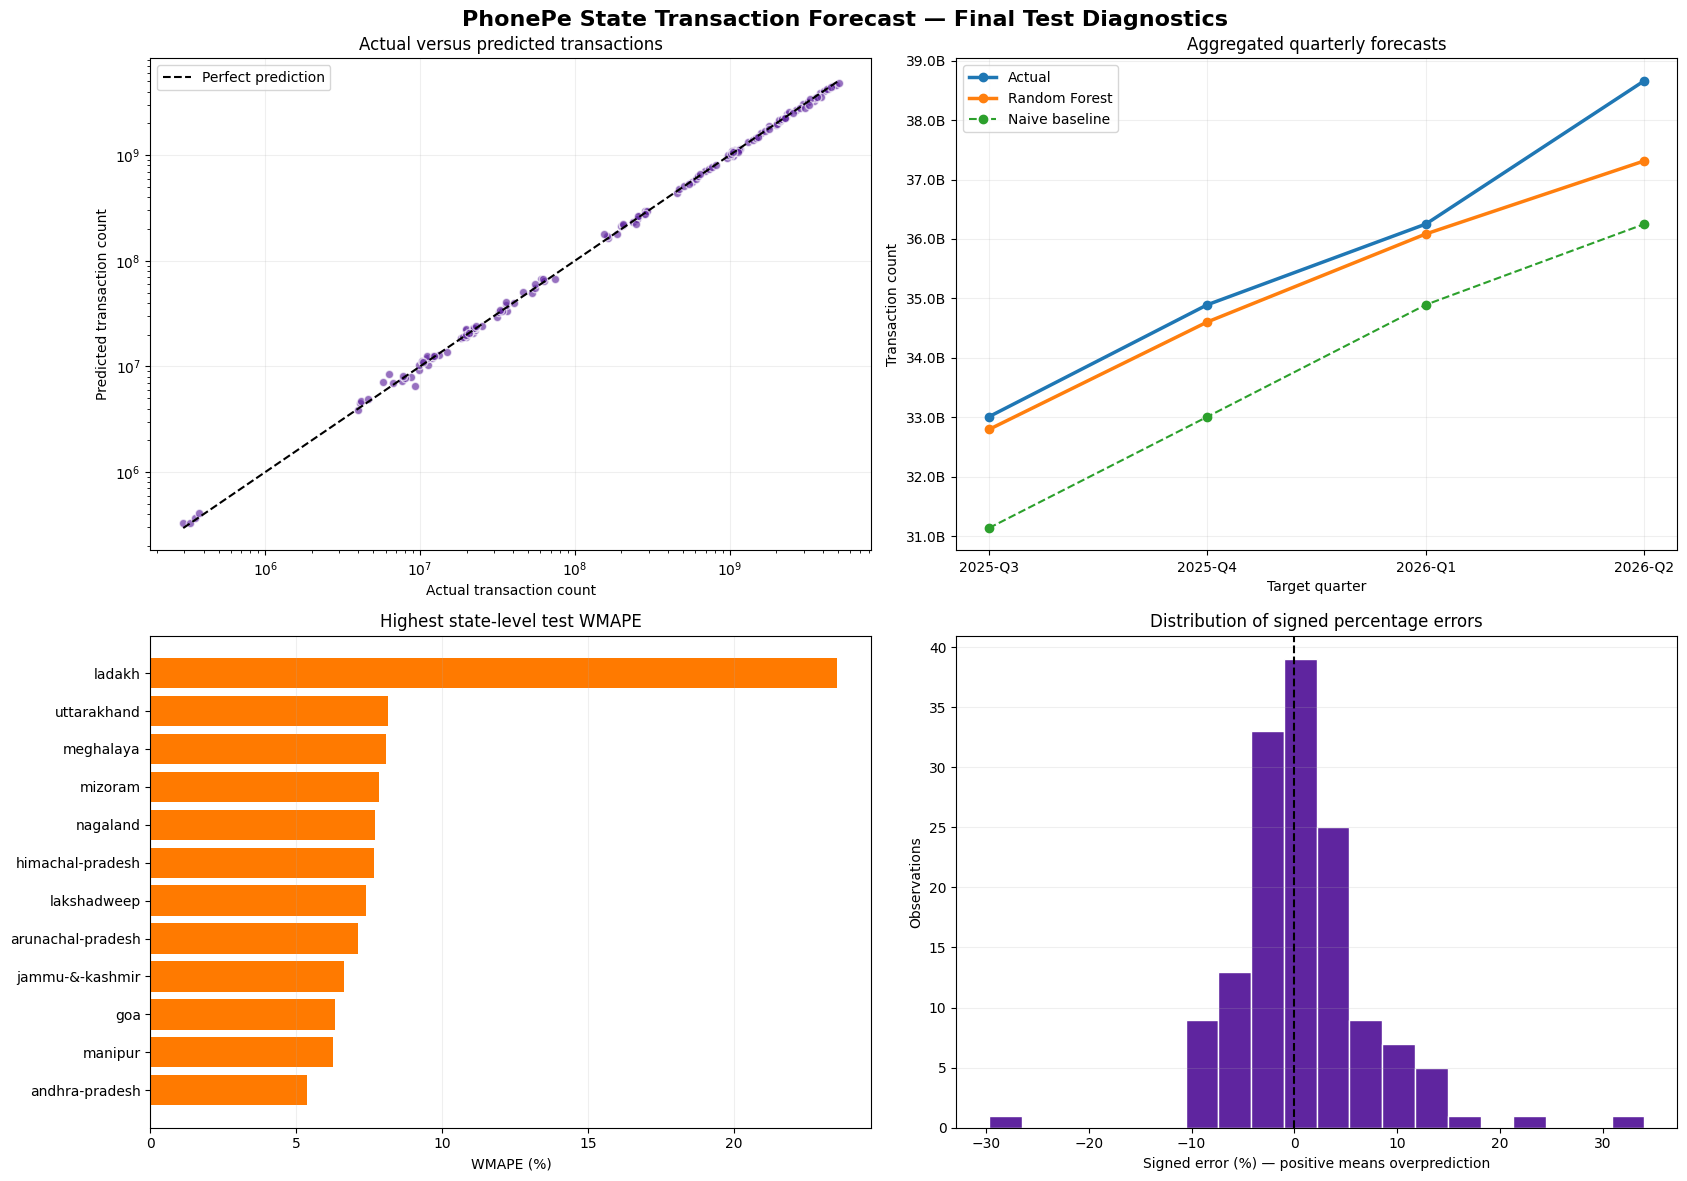

DIAGNOSTIC SUMMARY
Mean prediction bias: -14,027,286
Median signed percentage error: 0.08%
Overpredictions: 74
Underpredictions: 70


In [0]:
# ============================================================
# 10. FINAL MODEL DIAGNOSTICS
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

REQUIRED_COLUMNS = {
    "state_slug",
    "feature_period",
    "target_period",
    "target_next_quarter_transaction_count",
    "predicted_transaction_count",
    "last_quarter_naive_prediction"
}

# Automatically locate the full prediction DataFrame created earlier.
prediction_candidates = []

for variable_name, variable_value in list(globals().items()):
    if (
        isinstance(variable_value, pd.DataFrame)
        and REQUIRED_COLUMNS.issubset(variable_value.columns)
    ):
        prediction_candidates.append(
            (variable_name, variable_value)
        )

if not prediction_candidates:
    raise ValueError(
        "Could not find the full test-prediction DataFrame. "
        "Run the final training and evaluation cell again."
    )

# Select the candidate containing the most rows.
prediction_variable_name, test_diagnostics_pd = max(
    prediction_candidates,
    key=lambda item: len(item[1])
)

test_diagnostics_pd = test_diagnostics_pd.copy()

print(f"Prediction DataFrame: {prediction_variable_name}")
print(f"Rows                : {len(test_diagnostics_pd):,}")

ACTUAL_COLUMN = "target_next_quarter_transaction_count"
PREDICTED_COLUMN = "predicted_transaction_count"
NAIVE_COLUMN = "last_quarter_naive_prediction"

test_diagnostics_pd["absolute_error"] = (
    test_diagnostics_pd[PREDICTED_COLUMN]
    - test_diagnostics_pd[ACTUAL_COLUMN]
).abs()

test_diagnostics_pd["prediction_bias"] = (
    test_diagnostics_pd[PREDICTED_COLUMN]
    - test_diagnostics_pd[ACTUAL_COLUMN]
)

test_diagnostics_pd["signed_percentage_error"] = (
    100
    * test_diagnostics_pd["prediction_bias"]
    / test_diagnostics_pd[ACTUAL_COLUMN]
)

# ------------------------------------------------------------
# Performance by target quarter
# ------------------------------------------------------------

quarter_performance_pd = (
    test_diagnostics_pd
    .groupby("target_period", as_index=False)
    .agg(
        actual_transactions=(
            ACTUAL_COLUMN,
            "sum"
        ),
        predicted_transactions=(
            PREDICTED_COLUMN,
            "sum"
        ),
        naive_transactions=(
            NAIVE_COLUMN,
            "sum"
        ),
        absolute_error=(
            "absolute_error",
            "sum"
        ),
        prediction_bias=(
            "prediction_bias",
            "sum"
        )
    )
)

quarter_performance_pd["wmape_pct"] = (
    100
    * quarter_performance_pd["absolute_error"]
    / quarter_performance_pd["actual_transactions"]
)

quarter_performance_pd["aggregate_bias_pct"] = (
    100
    * quarter_performance_pd["prediction_bias"]
    / quarter_performance_pd["actual_transactions"]
)

# ------------------------------------------------------------
# Performance by state
# ------------------------------------------------------------

state_performance_pd = (
    test_diagnostics_pd
    .groupby("state_slug", as_index=False)
    .agg(
        observations=(
            ACTUAL_COLUMN,
            "size"
        ),
        actual_transactions=(
            ACTUAL_COLUMN,
            "sum"
        ),
        absolute_error=(
            "absolute_error",
            "sum"
        ),
        prediction_bias=(
            "prediction_bias",
            "sum"
        )
    )
)

state_performance_pd["wmape_pct"] = (
    100
    * state_performance_pd["absolute_error"]
    / state_performance_pd["actual_transactions"]
)

state_performance_pd["bias_pct"] = (
    100
    * state_performance_pd["prediction_bias"]
    / state_performance_pd["actual_transactions"]
)

state_performance_pd = state_performance_pd.sort_values(
    "wmape_pct",
    ascending=False
).reset_index(drop=True)

print("\n" + "=" * 70)
print("TEST PERFORMANCE BY TARGET QUARTER")
print("=" * 70)

display(
    quarter_performance_pd.style.format({
        "actual_transactions": "{:,.0f}",
        "predicted_transactions": "{:,.0f}",
        "naive_transactions": "{:,.0f}",
        "absolute_error": "{:,.0f}",
        "prediction_bias": "{:,.0f}",
        "wmape_pct": "{:.2f}%",
        "aggregate_bias_pct": "{:.2f}%"
    })
)

print("\n" + "=" * 70)
print("STATE-LEVEL TEST PERFORMANCE")
print("=" * 70)

display(
    state_performance_pd.style.format({
        "actual_transactions": "{:,.0f}",
        "absolute_error": "{:,.0f}",
        "prediction_bias": "{:,.0f}",
        "wmape_pct": "{:.2f}%",
        "bias_pct": "{:.2f}%"
    })
)

# ------------------------------------------------------------
# Diagnostic plots
# ------------------------------------------------------------

number_formatter = FuncFormatter(
    lambda value, position: f"{value / 1_000_000_000:.1f}B"
)

fig, axes = plt.subplots(
    2,
    2,
    figsize=(17, 12)
)

# Plot 1: actual versus predicted
minimum_value = min(
    test_diagnostics_pd[ACTUAL_COLUMN].min(),
    test_diagnostics_pd[PREDICTED_COLUMN].min()
)

maximum_value = max(
    test_diagnostics_pd[ACTUAL_COLUMN].max(),
    test_diagnostics_pd[PREDICTED_COLUMN].max()
)

axes[0, 0].scatter(
    test_diagnostics_pd[ACTUAL_COLUMN],
    test_diagnostics_pd[PREDICTED_COLUMN],
    alpha=0.65,
    color="#5f259f",
    edgecolor="white"
)

axes[0, 0].plot(
    [minimum_value, maximum_value],
    [minimum_value, maximum_value],
    linestyle="--",
    color="black",
    label="Perfect prediction"
)

axes[0, 0].set_xscale("log")
axes[0, 0].set_yscale("log")
axes[0, 0].set_title("Actual versus predicted transactions")
axes[0, 0].set_xlabel("Actual transaction count")
axes[0, 0].set_ylabel("Predicted transaction count")
axes[0, 0].legend()
axes[0, 0].grid(alpha=0.2)

# Plot 2: national totals by quarter
axes[0, 1].plot(
    quarter_performance_pd["target_period"],
    quarter_performance_pd["actual_transactions"],
    marker="o",
    linewidth=2.5,
    label="Actual"
)

axes[0, 1].plot(
    quarter_performance_pd["target_period"],
    quarter_performance_pd["predicted_transactions"],
    marker="o",
    linewidth=2.5,
    label="Random Forest"
)

axes[0, 1].plot(
    quarter_performance_pd["target_period"],
    quarter_performance_pd["naive_transactions"],
    marker="o",
    linestyle="--",
    label="Naive baseline"
)

axes[0, 1].set_title("Aggregated quarterly forecasts")
axes[0, 1].set_xlabel("Target quarter")
axes[0, 1].set_ylabel("Transaction count")
axes[0, 1].yaxis.set_major_formatter(number_formatter)
axes[0, 1].legend()
axes[0, 1].grid(alpha=0.2)

# Plot 3: states with the highest WMAPE
worst_states_pd = (
    state_performance_pd
    .head(12)
    .sort_values("wmape_pct")
)

axes[1, 0].barh(
    worst_states_pd["state_slug"],
    worst_states_pd["wmape_pct"],
    color="#ff7a00"
)

axes[1, 0].set_title("Highest state-level test WMAPE")
axes[1, 0].set_xlabel("WMAPE (%)")
axes[1, 0].grid(axis="x", alpha=0.2)

# Plot 4: signed errors
axes[1, 1].hist(
    test_diagnostics_pd["signed_percentage_error"],
    bins=20,
    color="#5f259f",
    edgecolor="white"
)

axes[1, 1].axvline(
    0,
    color="black",
    linestyle="--"
)

axes[1, 1].set_title("Distribution of signed percentage errors")
axes[1, 1].set_xlabel(
    "Signed error (%) — positive means overprediction"
)
axes[1, 1].set_ylabel("Observations")
axes[1, 1].grid(axis="y", alpha=0.2)

plt.suptitle(
    "PhonePe State Transaction Forecast — Final Test Diagnostics",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

print("=" * 70)
print("DIAGNOSTIC SUMMARY")
print("=" * 70)

print(
    f"Mean prediction bias: "
    f"{test_diagnostics_pd['prediction_bias'].mean():,.0f}"
)

print(
    f"Median signed percentage error: "
    f"{test_diagnostics_pd['signed_percentage_error'].median():.2f}%"
)

print(
    f"Overpredictions: "
    f"{(test_diagnostics_pd['prediction_bias'] > 0).sum():,}"
)

print(
    f"Underpredictions: "
    f"{(test_diagnostics_pd['prediction_bias'] < 0).sum():,}"
)

print("=" * 70)

Final model variable: final_model
Verification WMAPE: 2.82%

PERMUTATION FEATURE IMPORTANCE


,feature,importance_mean,importance_std,importance_mean_positive,relative_importance_pct
0,registered_user_qoq_growth_pct,0.004343,0.001749,0.004343,35.93%
1,transaction_qoq_growth_pct,0.002955,0.001265,0.002955,24.45%
2,transaction_yoy_growth_pct,0.001339,0.000750,0.001339,11.07%
3,transaction_rank,0.000782,0.000707,0.000782,6.47%
4,registered_merchant_qoq_growth_pct,0.000581,0.000284,0.000581,4.80%
5,rolling_4q_transaction_stddev,0.000535,0.000125,0.000535,4.43%
6,state_slug,0.000435,0.000161,0.000435,3.60%
7,registered_merchant_count,0.000312,0.000163,0.000312,2.58%
8,lag_3_transaction_count,0.000290,0.000210,0.000290,2.40%
9,quarter,0.000140,0.000145,0.000140,1.16%


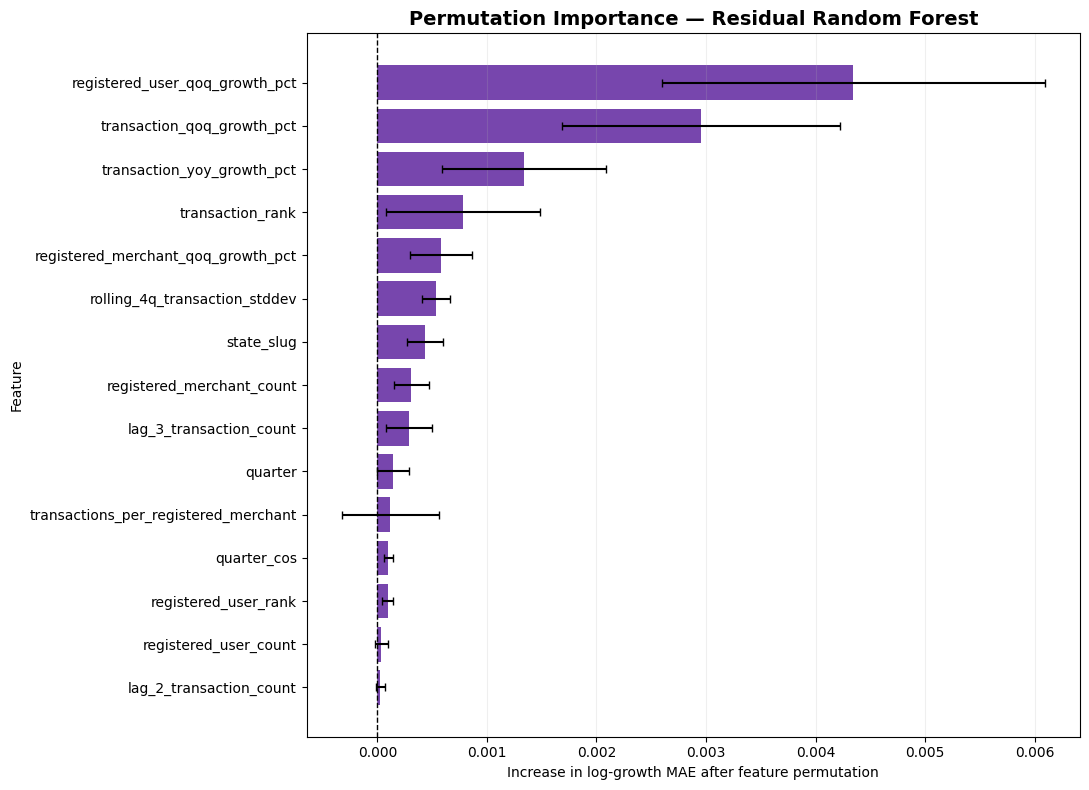


Top five forecasting drivers:
1. registered_user_qoq_growth_pct — 35.93% of positive importance
2. transaction_qoq_growth_pct — 24.45% of positive importance
3. transaction_yoy_growth_pct — 11.07% of positive importance
4. transaction_rank — 6.47% of positive importance
5. registered_merchant_qoq_growth_pct — 4.80% of positive importance


In [0]:
# ============================================================
# 11. PERMUTATION FEATURE IMPORTANCE
# ============================================================

from sklearn.inspection import permutation_importance
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Try the expected final-model variable names.
MODEL_VARIABLE_NAMES = [
    "final_residual_model",
    "final_model",
    "tuned_residual_model",
    "best_residual_model"
]

FINAL_MODEL = None
FINAL_MODEL_VARIABLE_NAME = None

for variable_name in MODEL_VARIABLE_NAMES:
    if (
        variable_name in globals()
        and hasattr(globals()[variable_name], "predict")
    ):
        FINAL_MODEL = globals()[variable_name]
        FINAL_MODEL_VARIABLE_NAME = variable_name
        break

if FINAL_MODEL is None:
    available_model_variables = [
        variable_name
        for variable_name, variable_value
        in list(globals().items())
        if hasattr(variable_value, "predict")
        and not isinstance(variable_value, type)
    ]

    raise ValueError(
        "Final model variable was not found. "
        f"Available model-like variables: "
        f"{available_model_variables}"
    )

print(f"Final model variable: {FINAL_MODEL_VARIABLE_NAME}")

# The residual model predicts:
# log(next-quarter transactions / current transactions)
test_log_growth_target = np.log(
    test_diagnostics_pd[
        "target_next_quarter_transaction_count"
    ].to_numpy()
    /
    test_diagnostics_pd[
        "total_transaction_count"
    ].to_numpy()
)

# Verify that we selected the correct fitted model.
predicted_log_growth = FINAL_MODEL.predict(X_test)

verification_forecast = (
    X_test["total_transaction_count"].to_numpy()
    * np.exp(predicted_log_growth)
)

verification_wmape = (
    100
    * np.abs(
        test_diagnostics_pd[
            "target_next_quarter_transaction_count"
        ].to_numpy()
        - verification_forecast
    ).sum()
    / test_diagnostics_pd[
        "target_next_quarter_transaction_count"
    ].sum()
)

print(f"Verification WMAPE: {verification_wmape:.2f}%")

assert abs(verification_wmape - 2.82) < 0.30, (
    "The selected model does not appear to be the final "
    "tuned residual Random Forest."
)

# Permutation importance is calculated on the untouched test set.
permutation_result = permutation_importance(
    estimator=FINAL_MODEL,
    X=X_test,
    y=test_log_growth_target,
    scoring="neg_mean_absolute_error",
    n_repeats=30,
    random_state=RANDOM_SEED,
    n_jobs=-1
)

feature_importance_pd = (
    pd.DataFrame({
        "feature": X_test.columns,
        "importance_mean": (
            permutation_result.importances_mean
        ),
        "importance_std": (
            permutation_result.importances_std
        )
    })
    .sort_values(
        "importance_mean",
        ascending=False
    )
    .reset_index(drop=True)
)

# Negative values mean that shuffling the feature did not
# consistently damage performance.
feature_importance_pd["importance_mean_positive"] = (
    feature_importance_pd["importance_mean"]
    .clip(lower=0)
)

total_positive_importance = (
    feature_importance_pd[
        "importance_mean_positive"
    ].sum()
)

if total_positive_importance > 0:
    feature_importance_pd[
        "relative_importance_pct"
    ] = (
        100
        * feature_importance_pd[
            "importance_mean_positive"
        ]
        / total_positive_importance
    )
else:
    feature_importance_pd[
        "relative_importance_pct"
    ] = 0.0

print("\n" + "=" * 70)
print("PERMUTATION FEATURE IMPORTANCE")
print("=" * 70)

display(
    feature_importance_pd.style.format({
        "importance_mean": "{:.6f}",
        "importance_std": "{:.6f}",
        "relative_importance_pct": "{:.2f}%"
    })
)

top_features_pd = (
    feature_importance_pd
    .head(15)
    .sort_values("importance_mean")
)

plt.figure(figsize=(11, 8))

plt.barh(
    top_features_pd["feature"],
    top_features_pd["importance_mean"],
    xerr=top_features_pd["importance_std"],
    color="#5f259f",
    alpha=0.85,
    capsize=3
)

plt.axvline(
    0,
    color="black",
    linestyle="--",
    linewidth=1
)

plt.title(
    "Permutation Importance — Residual Random Forest",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel(
    "Increase in log-growth MAE after feature permutation"
)

plt.ylabel("Feature")
plt.grid(axis="x", alpha=0.2)
plt.tight_layout()
plt.show()

print("\nTop five forecasting drivers:")

for position, row in (
    feature_importance_pd
    .head(5)
    .iterrows()
):
    print(
        f"{position + 1}. {row['feature']} — "
        f"{row['relative_importance_pct']:.2f}% "
        f"of positive importance"
    )

In [0]:
# ============================================================
# 12. LOG DEPLOYABLE MODEL AND RESULTS TO MLFLOW
# ============================================================

import mlflow
import mlflow.pyfunc
import sklearn
import pandas as pd
import numpy as np

from mlflow.models import infer_signature


# ------------------------------------------------------------
# 1. CALCULATE FINAL METRICS
# ------------------------------------------------------------

actual_test = test_diagnostics_pd[
    "target_next_quarter_transaction_count"
].to_numpy(dtype=float)

model_test_prediction = test_diagnostics_pd[
    "predicted_transaction_count"
].to_numpy(dtype=float)

naive_test_prediction = test_diagnostics_pd[
    "last_quarter_naive_prediction"
].to_numpy(dtype=float)

final_test_wmape = (
    100
    * np.abs(
        actual_test - model_test_prediction
    ).sum()
    / actual_test.sum()
)

naive_test_wmape = (
    100
    * np.abs(
        actual_test - naive_test_prediction
    ).sum()
    / actual_test.sum()
)

relative_improvement_pct = (
    100
    * (
        naive_test_wmape
        - final_test_wmape
    )
    / naive_test_wmape
)

print("=" * 70)
print("FINAL METRICS FOR MLFLOW")
print("=" * 70)
print(f"Model test WMAPE    : {final_test_wmape:.2f}%")
print(f"Naive test WMAPE    : {naive_test_wmape:.2f}%")
print(
    f"Relative improvement: "
    f"{relative_improvement_pct:.2f}%"
)


# ------------------------------------------------------------
# 2. CREATE DEPLOYMENT WRAPPER
# ------------------------------------------------------------

class PhonePeTransactionForecastModel(
    mlflow.pyfunc.PythonModel
):
    """
    Deployable wrapper around the residual-growth model.

    The underlying model predicts:

        log(next-quarter transactions / current transactions)

    This wrapper converts that value into the final
    next-quarter transaction-count forecast.
    """

    def __init__(self, residual_model):
        self.residual_model = residual_model

    def predict(
        self,
        context,
        model_input,
        params=None
    ):
        input_pd = model_input.copy()

        current_transactions = (
            input_pd["total_transaction_count"]
            .astype(float)
            .to_numpy()
        )

        predicted_log_growth = (
            self.residual_model.predict(input_pd)
        )

        predicted_transaction_count = (
            current_transactions
            * np.exp(predicted_log_growth)
        )

        predicted_transaction_count = np.clip(
            predicted_transaction_count,
            0,
            None
        )

        return pd.DataFrame({
            "predicted_next_quarter_transaction_count":
                predicted_transaction_count,

            "predicted_log_growth":
                predicted_log_growth,

            "predicted_growth_pct":
                100
                * (
                    np.exp(predicted_log_growth)
                    - 1
                )
        })


deployable_model = PhonePeTransactionForecastModel(
    residual_model=FINAL_MODEL
)


# ------------------------------------------------------------
# 3. CREATE INPUT EXAMPLE AND SIGNATURE
# ------------------------------------------------------------

input_example = (
    X_test
    .head(5)
    .copy()
)

output_example = deployable_model.predict(
    context=None,
    model_input=input_example
)

model_signature = infer_signature(
    model_input=input_example,
    model_output=output_example
)

print("\nInput example")
display(input_example)

print("\nOutput example")
display(output_example)


# ------------------------------------------------------------
# 4. SELECT MLFLOW EXPERIMENT
# ------------------------------------------------------------

EXPERIMENT_PATH = (
    "/Shared/phonepe_state_transaction_forecasting"
)

try:
    mlflow.set_experiment(EXPERIMENT_PATH)

    print(
        f"\nMLflow experiment: "
        f"{EXPERIMENT_PATH}"
    )

except Exception as experiment_error:
    print(
        "\nCould not create the Shared experiment."
    )

    print(
        "The notebook's default MLflow experiment "
        "will be used."
    )

    print(
        f"Reason: {experiment_error}"
    )


# Close an unfinished run, if one exists.
if mlflow.active_run() is not None:
    mlflow.end_run()


# ------------------------------------------------------------
# 5. LOG RUN, METRICS, TABLES AND MODEL
# ------------------------------------------------------------

with mlflow.start_run(
    run_name="tuned_residual_random_forest_final"
) as active_run:

    RUN_ID = active_run.info.run_id

    # Model and dataset configuration
    mlflow.log_params({
        "model_family":
            "Residual Random Forest",

        "prediction_target":
            "Next-quarter state transaction count",

        "residual_target":
            "log(next_quarter_count/current_count)",

        "training_period":
            "2021-Q1 to 2025-Q2",

        "test_period":
            "2025-Q3 to 2026-Q2",

        "training_rows":
            648,

        "test_rows":
            144,

        "state_count":
            36,

        "numerical_feature_count":
            21,

        "categorical_feature_count":
            1,

        "random_seed":
            RANDOM_SEED,

        "rf_max_depth":
            8,

        "rf_min_samples_leaf":
            3,

        "rf_max_features":
            0.8,

        "validation_strategy":
            "Rolling-origin temporal validation"
    })

    # Final model metrics
    mlflow.log_metrics({
        "test_wmape_pct":
            float(final_test_wmape),

        "naive_test_wmape_pct":
            float(naive_test_wmape),

        "relative_wmape_improvement_pct":
            float(relative_improvement_pct),

        "validation_wmape_pct":
            4.24,

        "rolling_validation_mean_wmape_pct":
            5.01,

        "median_signed_test_error_pct":
            float(
                test_diagnostics_pd[
                    "signed_percentage_error"
                ].median()
            )
    })

    # Log diagnostic datasets.
    mlflow.log_table(
        data=quarter_performance_pd,
        artifact_file=(
            "diagnostics/"
            "quarter_performance.json"
        )
    )

    mlflow.log_table(
        data=state_performance_pd,
        artifact_file=(
            "diagnostics/"
            "state_performance.json"
        )
    )

    mlflow.log_table(
        data=feature_importance_pd,
        artifact_file=(
            "diagnostics/"
            "permutation_feature_importance.json"
        )
    )

    mlflow.log_table(
        data=test_diagnostics_pd,
        artifact_file=(
            "predictions/"
            "untouched_test_predictions.json"
        )
    )

    pinned_requirements = [
        f"mlflow=={mlflow.__version__}",
        f"scikit-learn=={sklearn.__version__}",
        f"pandas=={pd.__version__}",
        f"numpy=={np.__version__}"
    ]

    # MLflow 3 uses the `name` argument.
    try:
        logged_model_info = (
            mlflow.pyfunc.log_model(
                name="phonepe_forecasting_model",
                python_model=deployable_model,
                input_example=input_example,
                signature=model_signature,
                pip_requirements=pinned_requirements
            )
        )

    # Compatibility fallback for older MLflow versions.
    except TypeError:
        logged_model_info = (
            mlflow.pyfunc.log_model(
                artifact_path=(
                    "phonepe_forecasting_model"
                ),
                python_model=deployable_model,
                input_example=input_example,
                signature=model_signature,
                pip_requirements=pinned_requirements
            )
        )

    MODEL_URI = logged_model_info.model_uri

print("\n" + "=" * 70)
print("MLFLOW LOGGING COMPLETED")
print("=" * 70)
print(f"Run ID   : {RUN_ID}")
print(f"Model URI: {MODEL_URI}")
print("=" * 70)


# ------------------------------------------------------------
# 6. RELOAD AND VERIFY THE LOGGED MODEL
# ------------------------------------------------------------

loaded_deployable_model = (
    mlflow.pyfunc.load_model(MODEL_URI)
)

reloaded_predictions = (
    loaded_deployable_model.predict(
        input_example
    )
)

expected_predictions = (
    output_example[
        "predicted_next_quarter_transaction_count"
    ].to_numpy()
)

actual_reloaded_predictions = (
    reloaded_predictions[
        "predicted_next_quarter_transaction_count"
    ].to_numpy()
)

np.testing.assert_allclose(
    actual_reloaded_predictions,
    expected_predictions,
    rtol=1e-8,
    atol=1e-5
)

print(
    "Logged model reload and prediction "
    "validation passed."
)

display(reloaded_predictions)

FINAL METRICS FOR MLFLOW
Model test WMAPE    : 2.82%
Naive test WMAPE    : 5.30%
Relative improvement: 46.86%

Input example


/databricks/python/lib/python3.12/site-packages/mlflow/pyfunc/utils/data_validation.py:187: UserWarning: Add type hints to the `predict` method to enable data validation and automatic signature inference during model logging. Check https://mlflow.org/docs/latest/model/python_model.html#type-hint-usage-in-pythonmodel for more details.
  color_warning(
/databricks/python/lib/python3.12/site-packages/mlflow/types/utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://ww

state_slug,quarter,time_index,quarter_sin,quarter_cos,total_transaction_count,registered_user_count,registered_merchant_count,transaction_yoy_growth_pct,transactions_per_registered_user,transactions_per_registered_merchant,transaction_rank,registered_user_rank,lag_1_transaction_count,lag_2_transaction_count,lag_3_transaction_count,lag_4_transaction_count,rolling_4q_transaction_mean,rolling_4q_transaction_stddev,transaction_qoq_growth_pct,registered_user_qoq_growth_pct,registered_merchant_qoq_growth_pct
andaman-&-nicobar-islands,2,30,1.2246467991473532E-16,-1.0,6375269,196844,4589,32.9402,32.3874,1389.2501634342993,34,35,6332082,6079801,5294506,4795590,5625494.75,708038.4069975181,0.6820347557090933,3.214778226969317,5.639963167587481
andhra-pradesh,2,30,1.2246467991473532E-16,-1.0,2530918973,31181805,1794867,31.7579,81.1665,1410.087194761506,5,11,2422886250,2292770050,2086058265,1920885662,2.18065005675E9,2.2186663715915814E8,4.458844198731993,2.863887483581662,3.1120902857766586
arunachal-pradesh,2,30,1.2246467991473532E-16,-1.0,31151454,803428,26579,54.9038,38.7732,1172.0325821136987,24,25,28407442,26790106,24519045,20110193,2.49566965E7,3603200.8877027193,9.65948289184222,3.942133909130785,7.2036461904569915
assam,2,30,1.2246467991473532E-16,-1.0,412522853,12266826,794454,50.2328,33.6291,519.2532896807115,17,18,381449165,333086043,297749691,274589008,3.2171847675E8,4.652120017172621E7,8.146219955678768,3.8813579646383323,4.263707304525388
bihar,2,30,1.2246467991473532E-16,-1.0,1793785807,38792069,2722198,35.7145,46.241,658.9475883091532,8,6,1530666231,1559808519,1354611186,1321734729,1.44170516625E9,1.208866413656312E8,17.18987266270984,4.117888445095552,3.1127403910802265



Output example


predicted_next_quarter_transaction_count,predicted_log_growth,predicted_growth_pct
7042623.986423469,0.09955453983666636,10.467871809385132
2.6463572947559586E9,0.04460162138648296,4.561122777436255
3.3431842388840802E7,0.07064788924260706,7.320327291434947
4.37582925607769E8,0.05897462663049069,6.07483256394743
1.8900390719014087E9,0.052269139404429746,5.36592855879412


...


MLflow experiment: /Shared/phonepe_state_transaction_forecasting


🔗 View Logged Model at: https://dbc-30917217-db8a.cloud.databricks.com/ml/experiments/1604593411151146/models/m-1bb64597370547e7add597525a867774?o=7474651413142179
2026/10/11 19:52:10 INFO mlflow.pyfunc: Validating input example against model signature



MLFLOW LOGGING COMPLETED
Run ID   : 0d9f9c946cf74b4f9c129007899b125f
Model URI: models:/m-1bb64597370547e7add597525a867774


Logged model reload and prediction validation passed.


predicted_next_quarter_transaction_count,predicted_log_growth,predicted_growth_pct
7042623.986423469,0.09955453983666637,10.467871809385132
2.6463572947559586E9,0.04460162138648295,4.561122777436255
3.3431842388840802E7,0.07064788924260706,7.320327291434947
4.37582925607769E8,0.058974626630490676,6.07483256394743
1.8900390719014087E9,0.052269139404429746,5.36592855879412


In [0]:
# ============================================================
# 13. REGISTER MODEL IN UNITY CATALOG
# ============================================================

import mlflow
import numpy as np

from mlflow import MlflowClient


# ------------------------------------------------------------
# 1. CONFIGURATION
# ------------------------------------------------------------

MODEL_CATALOG = "workspace"
MODEL_SCHEMA = "ml"

REGISTERED_MODEL_NAME = (
    f"{MODEL_CATALOG}."
    f"{MODEL_SCHEMA}."
    "phonepe_state_transaction_forecaster"
)

MODEL_ALIAS = "Champion"

print("=" * 70)
print("UNITY CATALOG MODEL REGISTRATION")
print("=" * 70)

print(f"Logged model URI : {MODEL_URI}")
print(f"Registered model : {REGISTERED_MODEL_NAME}")
print(f"Model alias      : {MODEL_ALIAS}")


# ------------------------------------------------------------
# 2. CREATE MODEL SCHEMA
# ------------------------------------------------------------

spark.sql(
    f"CREATE SCHEMA IF NOT EXISTS "
    f"{MODEL_CATALOG}.{MODEL_SCHEMA}"
)

print(
    f"\nSchema ready: "
    f"{MODEL_CATALOG}.{MODEL_SCHEMA}"
)


# ------------------------------------------------------------
# 3. USE UNITY CATALOG MODEL REGISTRY
# ------------------------------------------------------------

mlflow.set_registry_uri("databricks-uc")

print(
    f"Registry URI: "
    f"{mlflow.get_registry_uri()}"
)


# ------------------------------------------------------------
# 4. REGISTER MODEL VERSION
# ------------------------------------------------------------

registered_model_version = mlflow.register_model(
    model_uri=MODEL_URI,
    name=REGISTERED_MODEL_NAME,
    await_registration_for=300
)

MODEL_VERSION = str(
    registered_model_version.version
)

print("\nModel registration completed.")
print(f"Registered version: {MODEL_VERSION}")


# ------------------------------------------------------------
# 5. ADD DESCRIPTION, TAGS AND CHAMPION ALIAS
# ------------------------------------------------------------

registry_client = MlflowClient(
    registry_uri="databricks-uc"
)

registry_client.update_registered_model(
    name=REGISTERED_MODEL_NAME,
    description=(
        "Forecasts next-quarter PhonePe transaction "
        "counts for Indian states and union territories. "
        "The model uses a residual Random Forest trained "
        "on quarterly transaction, user and merchant "
        "growth features."
    )
)

registry_client.update_model_version(
    name=REGISTERED_MODEL_NAME,
    version=MODEL_VERSION,
    description=(
        "Tuned residual Random Forest. "
        "Training period: 2021-Q1 to 2025-Q2. "
        "Untouched test period: 2025-Q3 to 2026-Q2. "
        "Test WMAPE: 2.82%. "
        "Naive baseline WMAPE: 5.30%. "
        "Relative improvement: 46.86%."
    )
)

model_version_tags = {
    "model_family":
        "residual_random_forest",

    "prediction_target":
        "next_quarter_transaction_count",

    "training_period":
        "2021-Q1_to_2025-Q2",

    "test_period":
        "2025-Q3_to_2026-Q2",

    "test_wmape_pct":
        f"{final_test_wmape:.4f}",

    "naive_test_wmape_pct":
        f"{naive_test_wmape:.4f}",

    "validation_method":
        "rolling_origin",

    "deployment_status":
        "validated"
}

for tag_key, tag_value in model_version_tags.items():
    registry_client.set_model_version_tag(
        name=REGISTERED_MODEL_NAME,
        version=MODEL_VERSION,
        key=tag_key,
        value=str(tag_value)
    )

registry_client.set_registered_model_alias(
    name=REGISTERED_MODEL_NAME,
    alias=MODEL_ALIAS,
    version=MODEL_VERSION
)

print(
    f"Alias @{MODEL_ALIAS} assigned "
    f"to version {MODEL_VERSION}."
)


# ------------------------------------------------------------
# 6. LOAD MODEL USING CHAMPION ALIAS
# ------------------------------------------------------------

CHAMPION_MODEL_URI = (
    f"models:/{REGISTERED_MODEL_NAME}"
    f"@{MODEL_ALIAS}"
)

champion_model = mlflow.pyfunc.load_model(
    CHAMPION_MODEL_URI
)

champion_predictions = champion_model.predict(
    input_example
)

np.testing.assert_allclose(
    champion_predictions[
        "predicted_next_quarter_transaction_count"
    ].to_numpy(),

    output_example[
        "predicted_next_quarter_transaction_count"
    ].to_numpy(),

    rtol=1e-8,
    atol=1e-5
)

print("\n" + "=" * 70)
print("REGISTERED MODEL VALIDATION PASSED")
print("=" * 70)

print(f"Registered model: {REGISTERED_MODEL_NAME}")
print(f"Version         : {MODEL_VERSION}")
print(f"Champion URI    : {CHAMPION_MODEL_URI}")

print("=" * 70)

display(champion_predictions)

UNITY CATALOG MODEL REGISTRATION
Logged model URI : models:/m-1bb64597370547e7add597525a867774
Registered model : workspace.ml.phonepe_state_transaction_forecaster
Model alias      : Champion

Schema ready: workspace.ml
Registry URI: databricks-uc


Successfully registered model 'workspace.ml.phonepe_state_transaction_forecaster'.


Uploading artifacts:   0%|          | 0/12 [00:00<?, ?it/s]

🔗 Created version '1' of model 'workspace.ml.phonepe_state_transaction_forecaster': https://dbc-30917217-db8a.cloud.databricks.com/explore/data/models/workspace/ml/phonepe_state_transaction_forecaster/version/1?o=7474651413142179



Model registration completed.
Registered version: 1
Alias @Champion assigned to version 1.



REGISTERED MODEL VALIDATION PASSED
Registered model: workspace.ml.phonepe_state_transaction_forecaster
Version         : 1
Champion URI    : models:/workspace.ml.phonepe_state_transaction_forecaster@Champion


predicted_next_quarter_transaction_count,predicted_log_growth,predicted_growth_pct
7042623.986423469,0.09955453983666637,10.467871809385132
2.6463572947559586E9,0.04460162138648295,4.561122777436255
3.3431842388840802E7,0.07064788924260706,7.320327291434947
4.37582925607769E8,0.058974626630490676,6.07483256394743
1.8900390719014087E9,0.05226913940442975,5.36592855879412
